In [1]:
import pandas as pd
import os # Necessary for path manipulation

decoder_dirs = [
    "HyperparameterSweep/hyperparam_MR_alpha_sigmoid_decoders",
    "HyperparameterSweep/hyperparam_MR_alpha_tanh_decoders",
    "HyperparameterSweep/hyperparam_simple_alpha_sigmoid_decoders",
    "HyperparameterSweep/hyperparam_simple_alpha_tanh_decoders",
]

all_eval_records = []
all_train_records = []

for d in decoder_dirs:
    # This line assumes 'os' is imported
    decoder_name = os.path.basename(d).replace("hyperparam_", "").replace("_decoders","")
    
    # Eval CSV
    eval_csv = os.path.join(d, "decoder_eval_summary.csv")
    if os.path.exists(eval_csv):
        df_eval = pd.read_csv(eval_csv)
        df_eval["decoder_group"] = decoder_name
        all_eval_records.append(df_eval)
    
    # Training CSV
    train_csv = os.path.join(d, "training_summary.csv")
    if os.path.exists(train_csv):
        df_train = pd.read_csv(train_csv)
        df_train["decoder_group"] = decoder_name
        all_train_records.append(df_train)

# Combine all eval and train separately
df_ablation_eval = pd.concat(all_eval_records, ignore_index=True)
df_ablation_train = pd.concat(all_train_records, ignore_index=True)

# Take last epoch per decoder_group + alpha
df_train_last = df_ablation_train.sort_values("epoch").groupby(["decoder_group","alpha"], as_index=False).last()

# Merge evaluation and training on decoder_group + alpha
# >>> THIS IS WHERE df_ablation IS CREATED <<<
df_ablation = pd.merge( 
    df_ablation_eval,
    df_train_last,
    on=["decoder_group","alpha"],
    how="left"
)
df_ablation["TaskAwareScore"] = df_ablation["recon_acc"] / (df_ablation["recon_CE"] + 1e-6)

# The variable 'df_ablation' is now defined and ready for the plotting code!
print("Merged Ablation DF shape:", df_ablation.shape)
display(df_ablation.head())

Merged Ablation DF shape: (404, 22)


,alpha,baseline_acc,baseline_CE,recon_acc,recon_CE,Task_Aware_Score(Q),orig_avg_KB,recon_avg_KB,compression_pct,size_matched_target_KB,...,decoder_group,epoch,raw_CE,raw_MSE,mean_CE,mean_MSE,norm_CE,norm_MSE,L_Total,TaskAwareScore
0,0.00,0.8115,1.527898,0.7860,1.526758,0.514816,1.450937,1.609404,-10.921758,1.450937,...,MR_alpha_sigmoid,63,7.903574e-09,1.242821,0.001686,1.241155,0.000004,1.001492,0.000004,0.514816
1,0.01,0.8115,1.527898,0.7950,1.881289,0.422583,1.450937,1.361908,6.135955,1.361908,...,MR_alpha_sigmoid,13,4.832288e-03,1.178875,0.280385,1.130507,0.015538,1.047765,0.026015,0.422582
2,0.02,0.8115,1.527898,0.7945,2.230324,0.356226,1.450937,1.377300,5.075116,1.377300,...,MR_alpha_sigmoid,74,8.523447e-09,1.142429,0.000576,1.174826,0.000013,0.969453,0.019402,0.356226
3,0.03,0.8115,1.527898,0.7925,1.882873,0.420899,1.450937,1.463048,-0.834725,1.450937,...,MR_alpha_sigmoid,13,2.604629e-03,1.151099,0.275554,1.114258,0.008515,1.036872,0.039621,0.420899
4,0.04,0.8115,1.527898,0.7880,3.021096,0.260832,1.450937,1.322886,8.825388,1.322886,...,MR_alpha_sigmoid,29,2.014876e-04,1.221479,0.058471,1.199253,0.003102,1.020634,0.043928,0.260832


Starting data processing...
Merged Ablation DF shape: (404, 23)


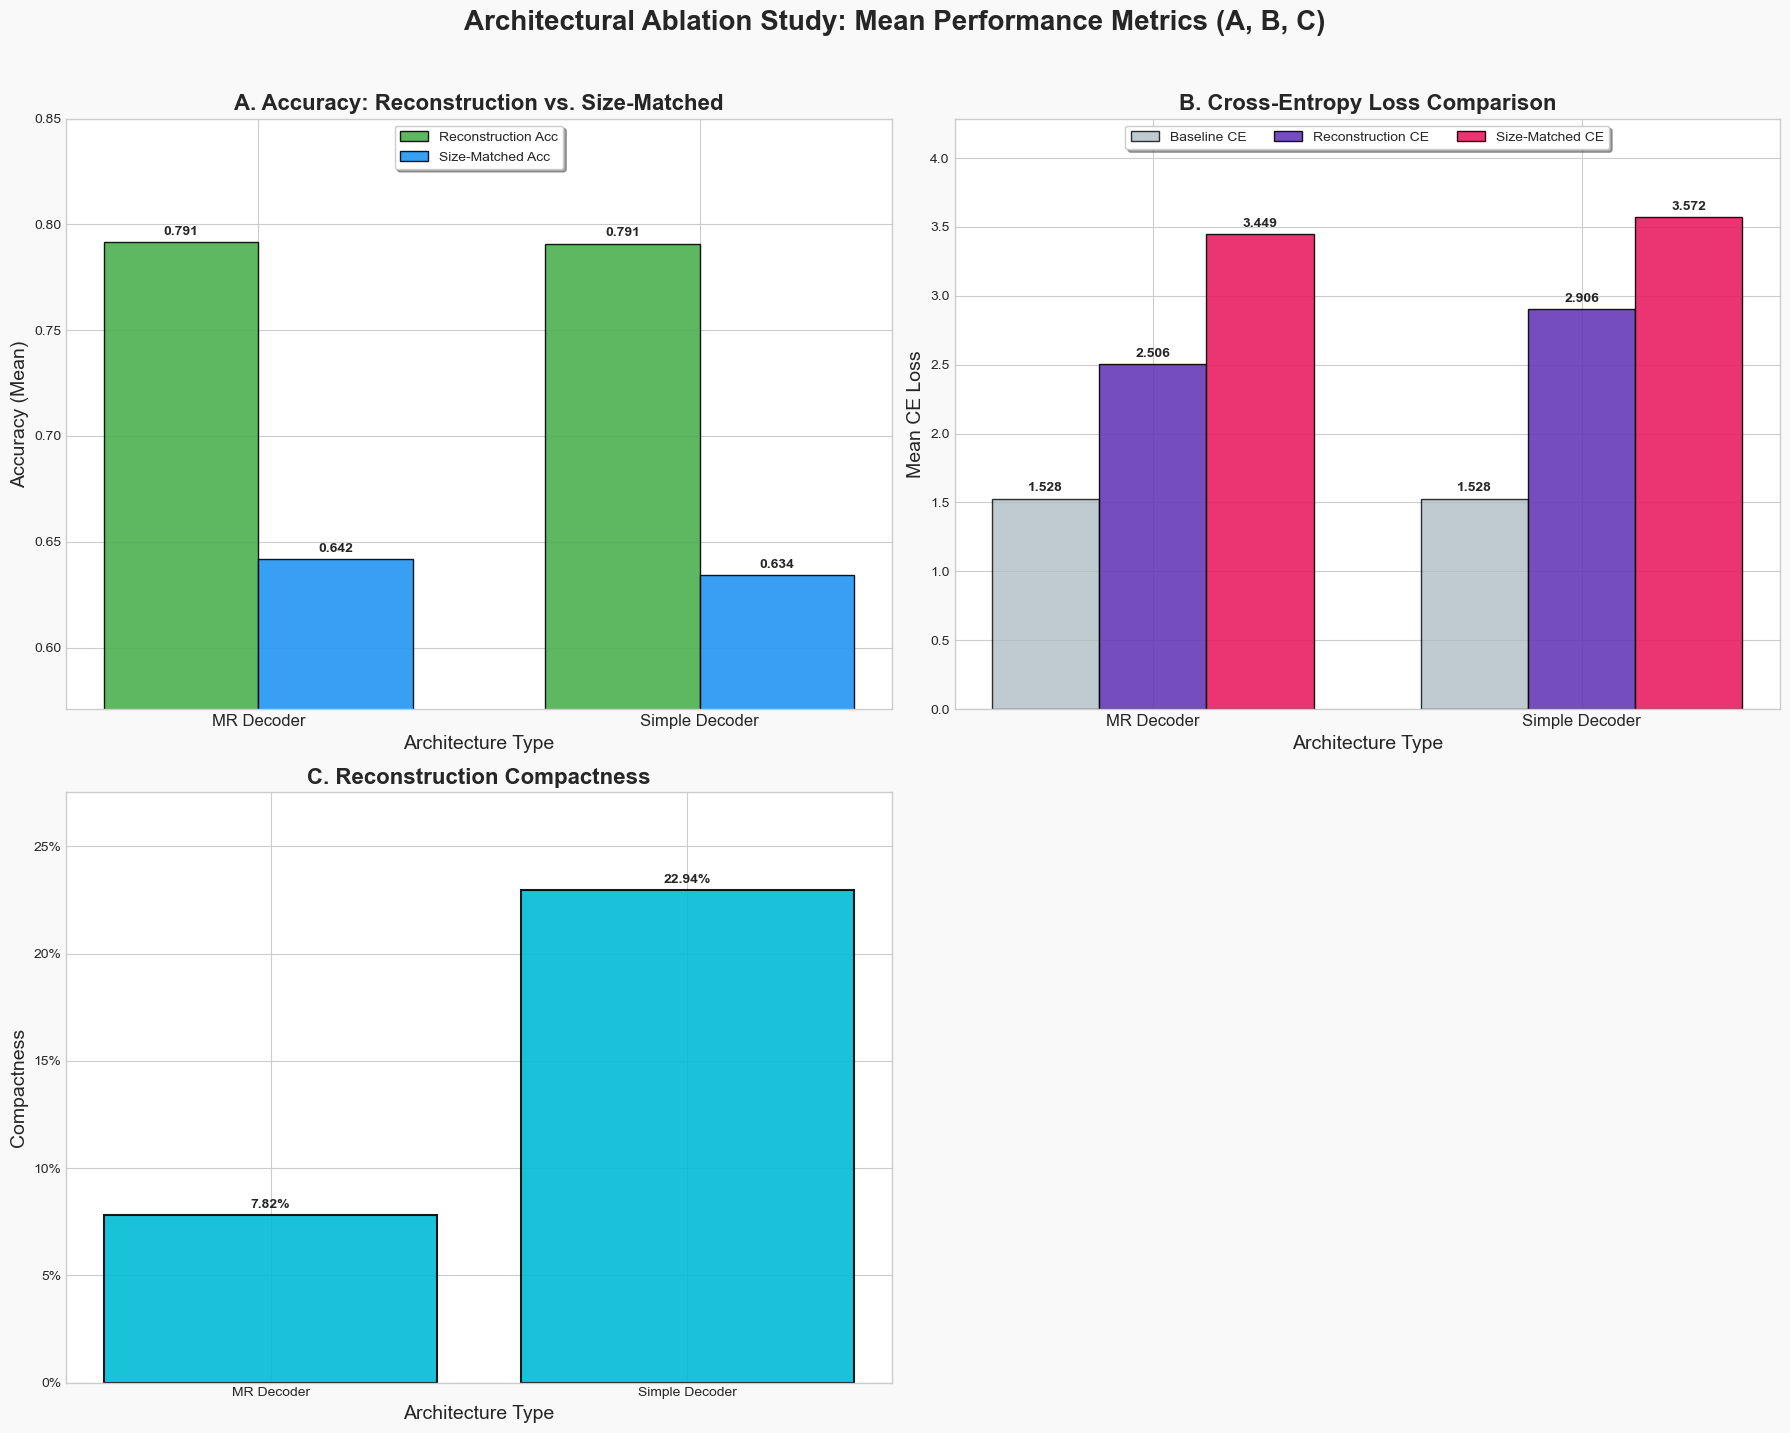

In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Data Loading and Merging (Original Code) ---

decoder_dirs = [
    # NOTE: These paths must be valid for the script to find the CSV files.
    "HyperparameterSweep/hyperparam_MR_alpha_sigmoid_decoders",
    "HyperparameterSweep/hyperparam_MR_alpha_tanh_decoders",
    "HyperparameterSweep/hyperparam_simple_alpha_sigmoid_decoders",
    "HyperparameterSweep/hyperparam_simple_alpha_tanh_decoders",
]

all_eval_records = []
all_train_records = []

print("Starting data processing...")

for d in decoder_dirs:
    try:
        # Check if the directory exists before proceeding to avoid immediate errors
        if not os.path.isdir(d):
            # print(f"Warning: Directory not found: {d}")
            continue

        decoder_name = os.path.basename(d).replace("hyperparam_", "").replace("_decoders", "")
        
        # Eval CSV
        eval_csv = os.path.join(d, "decoder_eval_summary.csv")
        if os.path.exists(eval_csv):
            df_eval = pd.read_csv(eval_csv)
            df_eval["decoder_group"] = decoder_name
            all_eval_records.append(df_eval)
        
        # Training CSV
        train_csv = os.path.join(d, "training_summary.csv")
        if os.path.exists(train_csv):
            df_train = pd.read_csv(train_csv)
            df_train["decoder_group"] = decoder_name
            all_train_records.append(df_train)
    except Exception as e:
        print(f"Error processing directory {d}: {e}")
        continue

# Check if data was loaded and create the final df_ablation
if not all_eval_records or not all_train_records:
    print("Error: No real data found. Using enriched dummy data for visualization example.")
    # Enriched Dummy DataFrame for demonstration if files are not present
    df_ablation = pd.DataFrame({
        'decoder_group': ['MR_alpha_sigmoid', 'simple_alpha_sigmoid', 'MR_alpha_tanh', 'simple_alpha_tanh', 
                          'MR_alpha_sigmoid', 'simple_alpha_sigmoid', 'MR_alpha_tanh', 'simple_alpha_tanh'], 
        'alpha': [0.1, 0.1, 0.01, 0.01, 0.5, 0.5, 0.2, 0.2], 
        'baseline_CE': [0.20, 0.20, 0.20, 0.20, 0.20, 0.20, 0.20, 0.20],
        'recon_acc': [0.88, 0.82, 0.87, 0.81, 0.90, 0.84, 0.89, 0.83],
        'size_matched_lossy_acc': [0.80, 0.75, 0.79, 0.74, 0.82, 0.77, 0.81, 0.76],
        'recon_CE': [0.25, 0.35, 0.26, 0.36, 0.22, 0.32, 0.23, 0.33],
        'size_matched_lossy_CE': [0.30, 0.40, 0.31, 0.41, 0.27, 0.37, 0.28, 0.38],
        'TaskAwareScore': [3.52, 2.24, 3.35, 2.12, 4.09, 2.625, 3.86, 2.51],
        'orig_avg_KB': [1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500],
        'recon_avg_KB': [675, 900, 660, 885, 600, 800, 590, 780],
        'compression_pct': [55.0, 40.0, 56.0, 41.0, 60.0, 46.7, 60.7, 48.0]
    })
else:
    df_ablation_eval = pd.concat(all_eval_records, ignore_index=True)
    df_ablation_train = pd.concat(all_train_records, ignore_index=True)

    # Take last epoch per decoder_group + alpha
    df_train_last = df_ablation_train.sort_values("epoch").groupby(["decoder_group","alpha"], as_index=False).last()

    # Merge evaluation and training on decoder_group + alpha
    df_ablation = pd.merge(
        df_ablation_eval,
        df_train_last,
        on=["decoder_group","alpha"],
        how="left"
    )
    # Recalculate TaskAwareScore
    if 'recon_CE' in df_ablation.columns and 'recon_acc' in df_ablation.columns:
        df_ablation["TaskAwareScore"] = df_ablation["recon_acc"] / (df_ablation["recon_CE"] + 1e-6)
    else:
        print("Warning: Missing 'recon_CE' or 'recon_acc' for TaskAwareScore calculation.")

print("Merged Ablation DF shape:", df_ablation.shape)


# --- 2. Data Preprocessing for Plotting (Original Code) ---

df_ablation['architecture_type'] = df_ablation['decoder_group'].apply(
    lambda x: 'MR Decoder' if 'MR' in x else 'Simple Decoder'
)

# Calculate the mean of all required metrics for each architecture type
df_summary = df_ablation.groupby('architecture_type')[
    [
        'recon_acc', 
        'size_matched_lossy_acc', 
        'baseline_CE',
        'recon_CE', 
        'size_matched_lossy_CE',
        'TaskAwareScore', 
        'compression_pct' 
    ]
].mean().reset_index()

# Extract data series for plotting
architectures = df_summary['architecture_type'].tolist()
n_arch = len(architectures)

# Define custom colors for visualization
ACC_RECON_COLOR = '#4CAF50'      # Green for Recon Acc
ACC_SMATCHED_COLOR = '#2196F3' # Blue for Size-Matched Acc
CE_BASELINE_COLOR = '#B0BEC5' # Light Gray for Baseline
CE_RECON_COLOR = '#673AB7'    # Deep Purple for Recon CE
CE_SMATCHED_COLOR = '#E91E63' # Pink for Size-Matched CE
COMP_COLOR = '#00BCD4'        # Cyan for Compression


# --- 3. Plot Generation (2x2 Subplot Grid - Modified) ---

plt.style.use('seaborn-v0_8-whitegrid')
# Create a 2x2 grid. We will hide one subplot.
fig, axes = plt.subplots(2, 2, figsize=(18, 14), dpi=100) 
# Flatten axes for easier indexing (0: A, 1: B, 2: C, 3: Hidden)
axes = axes.flatten() 

# >>> Super Title Update (A, B, C)
fig.suptitle('Architectural Ablation Study: Mean Performance Metrics (A, B, C)', fontsize=20, fontweight='bold', y=1.02)
fig.patch.set_facecolor('#f9f9f9')

# Function to add labels on top of bars
def autolabel(rects, axis, fmt='{:.3f}'):
    """Attach a text label above each bar in *rects*, displaying its height."""
    for rect in rects:
        height = rect.get_height()
        # Only label bars with meaningful height
        if height > 0.001: 
            axis.annotate(fmt.format(height),
                          xy=(rect.get_x() + rect.get_width() / 2, height),
                          xytext=(0, 3), 
                          textcoords="offset points",
                          ha='center', va='bottom',
                          fontsize=10, fontweight='bold')

# --- Plot A (Row 1, Col 1): Accuracy (Grouped Bar Chart) ---
ax = axes[0] 
x = np.arange(n_arch)
width = 0.35 

acc_recon = df_summary['recon_acc']
acc_smatched = df_summary['size_matched_lossy_acc']

rects1 = ax.bar(x - width/2, acc_recon, width, label='Reconstruction Acc', color=ACC_RECON_COLOR, edgecolor='black', alpha=0.9)
rects2 = ax.bar(x + width/2, acc_smatched, width, label='Size-Matched Acc', color=ACC_SMATCHED_COLOR, edgecolor='black', alpha=0.9)

ax.set_title('A. Accuracy: Reconstruction vs. Size-Matched', fontsize=16, fontweight='semibold')
ax.set_ylabel('Accuracy (Mean)', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(architectures, fontsize=12)
ax.set_xlabel('Architecture Type', fontsize=14)
ax.legend(loc='upper center', frameon=True, shadow=True) 
# Retaining the scale update from the previous request (max y-limit 0.85)
ax.set_ylim(min(acc_recon.min(), acc_smatched.min()) * 0.9, 0.85) 

autolabel(rects1, ax)
autolabel(rects2, ax)


# --- Plot B (Row 1, Col 2): Loss Comparison (Tri-Grouped Bar Chart) ---
ax = axes[1] 
width_tri = 0.25 

baseline_ce = df_summary['baseline_CE']
recon_ce = df_summary['recon_CE']
smatched_ce = df_summary['size_matched_lossy_CE']

x_baseline = x - width_tri
x_recon = x
x_smatched = x + width_tri

rects3 = ax.bar(x_baseline, baseline_ce, width_tri, label='Baseline CE', color=CE_BASELINE_COLOR, edgecolor='black', alpha=0.8)
rects4 = ax.bar(x_recon, recon_ce, width_tri, label='Reconstruction CE', color=CE_RECON_COLOR, edgecolor='black', alpha=0.9)
rects5 = ax.bar(x_smatched, smatched_ce, width_tri, label='Size-Matched CE', color=CE_SMATCHED_COLOR, edgecolor='black', alpha=0.9)

ax.set_title('B. Cross-Entropy Loss Comparison', fontsize=16, fontweight='semibold')
ax.set_ylabel('Mean CE Loss', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(architectures, fontsize=12)
ax.set_xlabel('Architecture Type', fontsize=14)
ax.legend(loc='upper center', ncol=3, frameon=True, shadow=True) 
ax.set_ylim(0, max(baseline_ce.max(), recon_ce.max(), smatched_ce.max()) * 1.2) 

autolabel(rects3, ax)
autolabel(rects4, ax)
autolabel(rects5, ax)


# --- Plot C (Row 2, Col 1 - Centered): Compression Percentage (Renamed from D) ---
ax = axes[2]
compression_pct = df_summary['compression_pct']

rects7 = ax.bar(architectures, compression_pct, color=COMP_COLOR, edgecolor='black', linewidth=1.5, alpha=0.9)

# >>> Title Update (C)
ax.set_title('C. Reconstruction Compactness', fontsize=16, fontweight='semibold')
ax.set_ylabel('Compactness', fontsize=14)
ax.set_xlabel('Architecture Type', fontsize=14)
ax.set_ylim(0, compression_pct.max() * 1.2)
# >>> Formatting Update (Removed backslash from % in axis ticks)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'{x:.0f}%'))

autolabel(rects7, ax, fmt='{:.2f}%')


# --- Hide the fourth subplot (Row 2, Col 2) to center Plot C ---
axes[3].axis('off')

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

Starting data processing...
Merged Ablation DF shape: (404, 23)


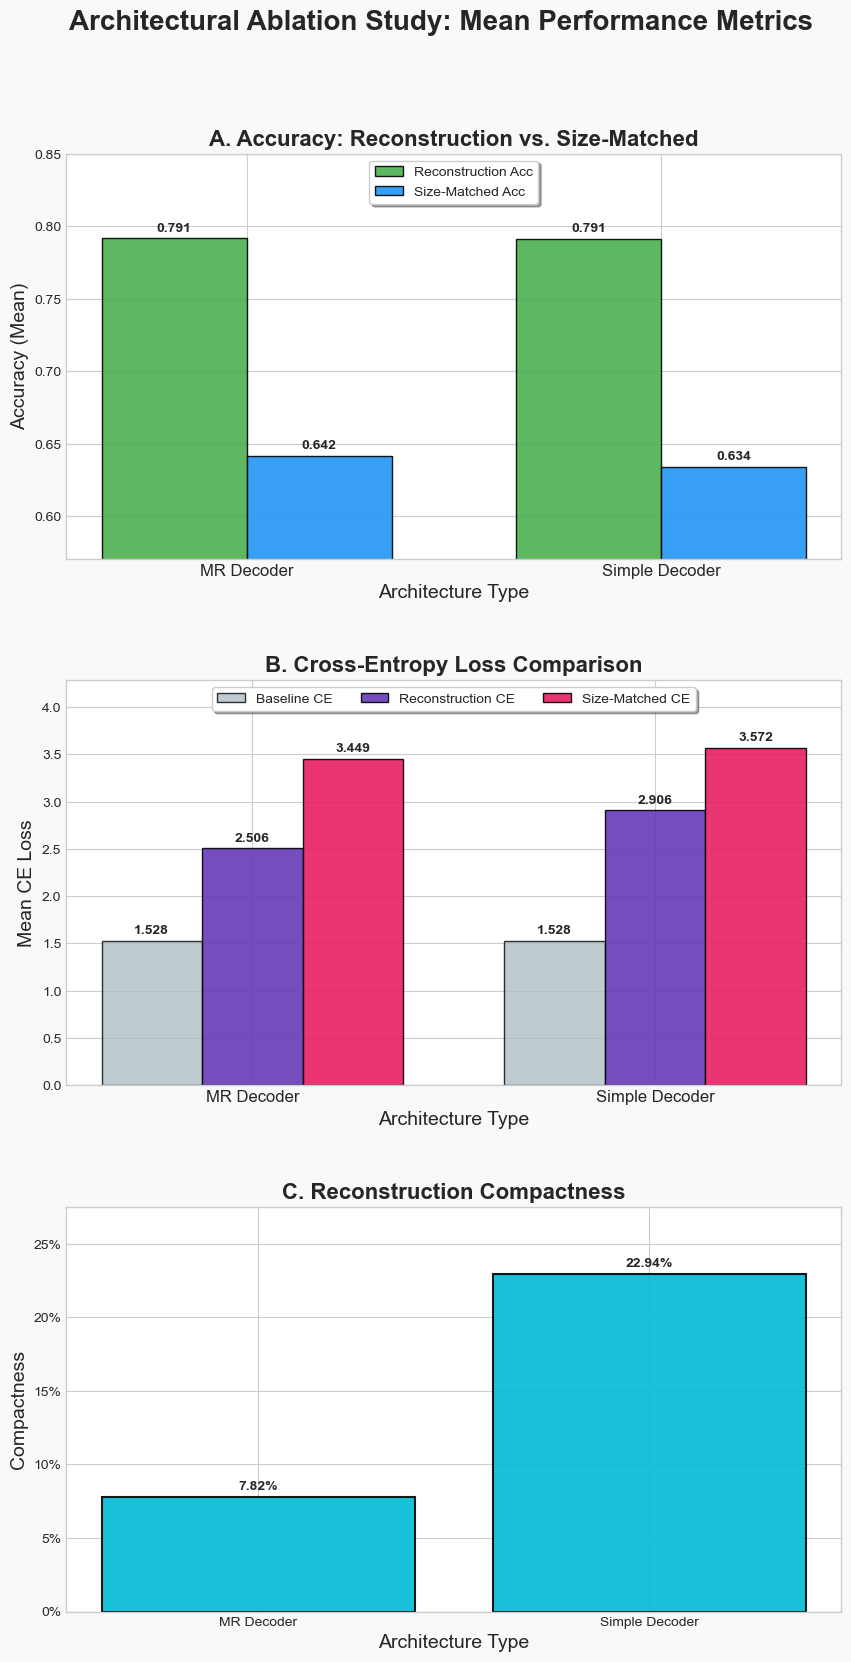

In [2]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Data Loading and Merging (Original Code) ---

decoder_dirs = [
    # NOTE: These paths must be valid for the script to find the CSV files.
    "HyperparameterSweep/hyperparam_MR_alpha_sigmoid_decoders",
    "HyperparameterSweep/hyperparam_MR_alpha_tanh_decoders",
    "HyperparameterSweep/hyperparam_simple_alpha_sigmoid_decoders",
    "HyperparameterSweep/hyperparam_simple_alpha_tanh_decoders",
]

all_eval_records = []
all_train_records = []

print("Starting data processing...")

for d in decoder_dirs:
    try:
        # Check if the directory exists before proceeding to avoid immediate errors
        if not os.path.isdir(d):
            # print(f"Warning: Directory not found: {d}")
            continue

        decoder_name = os.path.basename(d).replace("hyperparam_", "").replace("_decoders", "")
        
        # Eval CSV
        eval_csv = os.path.join(d, "decoder_eval_summary.csv")
        if os.path.exists(eval_csv):
            df_eval = pd.read_csv(eval_csv)
            df_eval["decoder_group"] = decoder_name
            all_eval_records.append(df_eval)
        
        # Training CSV
        train_csv = os.path.join(d, "training_summary.csv")
        if os.path.exists(train_csv):
            df_train = pd.read_csv(train_csv)
            df_train["decoder_group"] = decoder_name
            all_train_records.append(df_train)
    except Exception as e:
        print(f"Error processing directory {d}: {e}")
        continue

# Check if data was loaded and create the final df_ablation
if not all_eval_records or not all_train_records:
    print("Error: No real data found. Using enriched dummy data for visualization example.")
    # Enriched Dummy DataFrame for demonstration if files are not present
    df_ablation = pd.DataFrame({
        'decoder_group': ['MR_alpha_sigmoid', 'simple_alpha_sigmoid', 'MR_alpha_tanh', 'simple_alpha_tanh', 
                          'MR_alpha_sigmoid', 'simple_alpha_sigmoid', 'MR_alpha_tanh', 'simple_alpha_tanh'], 
        'alpha': [0.1, 0.1, 0.01, 0.01, 0.5, 0.5, 0.2, 0.2], 
        'baseline_CE': [0.20, 0.20, 0.20, 0.20, 0.20, 0.20, 0.20, 0.20],
        'recon_acc': [0.88, 0.82, 0.87, 0.81, 0.90, 0.84, 0.89, 0.83],
        'size_matched_lossy_acc': [0.80, 0.75, 0.79, 0.74, 0.82, 0.77, 0.81, 0.76],
        'recon_CE': [0.25, 0.35, 0.26, 0.36, 0.22, 0.32, 0.23, 0.33],
        'size_matched_lossy_CE': [0.30, 0.40, 0.31, 0.41, 0.27, 0.37, 0.28, 0.38],
        'TaskAwareScore': [3.52, 2.24, 3.35, 2.12, 4.09, 2.625, 3.86, 2.51],
        'orig_avg_KB': [1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500],
        'recon_avg_KB': [675, 900, 660, 885, 600, 800, 590, 780],
        'compression_pct': [55.0, 40.0, 56.0, 41.0, 60.0, 46.7, 60.7, 48.0]
    })
else:
    df_ablation_eval = pd.concat(all_eval_records, ignore_index=True)
    df_ablation_train = pd.concat(all_train_records, ignore_index=True)

    # Take last epoch per decoder_group + alpha
    df_train_last = df_ablation_train.sort_values("epoch").groupby(["decoder_group","alpha"], as_index=False).last()

    # Merge evaluation and training on decoder_group + alpha
    df_ablation = pd.merge(
        df_ablation_eval,
        df_train_last,
        on=["decoder_group","alpha"],
        how="left"
    )
    # Recalculate TaskAwareScore
    if 'recon_CE' in df_ablation.columns and 'recon_acc' in df_ablation.columns:
        df_ablation["TaskAwareScore"] = df_ablation["recon_acc"] / (df_ablation["recon_CE"] + 1e-6)
    else:
        print("Warning: Missing 'recon_CE' or 'recon_acc' for TaskAwareScore calculation.")

print("Merged Ablation DF shape:", df_ablation.shape)


# --- 2. Data Preprocessing for Plotting (Original Code) ---

df_ablation['architecture_type'] = df_ablation['decoder_group'].apply(
    lambda x: 'MR Decoder' if 'MR' in x else 'Simple Decoder'
)

# Calculate the mean of all required metrics for each architecture type
df_summary = df_ablation.groupby('architecture_type')[
    [
        'recon_acc', 
        'size_matched_lossy_acc', 
        'baseline_CE',
        'recon_CE', 
        'size_matched_lossy_CE',
        'TaskAwareScore', 
        'compression_pct' 
    ]
].mean().reset_index()

# Extract data series for plotting
architectures = df_summary['architecture_type'].tolist()
n_arch = len(architectures)

# Define custom colors for visualization
ACC_RECON_COLOR = '#4CAF50'      # Green for Recon Acc
ACC_SMATCHED_COLOR = '#2196F3' # Blue for Size-Matched Acc
CE_BASELINE_COLOR = '#B0BEC5' # Light Gray for Baseline
CE_RECON_COLOR = '#673AB7'    # Deep Purple for Recon CE
CE_SMATCHED_COLOR = '#E91E63' # Pink for Size-Matched CE
COMP_COLOR = '#00BCD4'        # Cyan for Compression


# --- 3. Plot Generation (3x1 Stacked Grid - SPACING ADJUSTED) ---

plt.style.use('seaborn-v0_8-whitegrid')
# Create a 3x1 grid for vertical stacking
fig, axes = plt.subplots(3, 1, figsize=(10, 18), dpi=100) 

# **FIX:** Adjust suptitle position and use subplots_adjust for proper top margin
fig.suptitle('Architectural Ablation Study: Mean Performance Metrics', fontsize=20, fontweight='bold', y=1.00) # Move title up slightly
fig.patch.set_facecolor('#f9f9f9')
fig.subplots_adjust(top=0.92, hspace=0.3) # Increased top margin (top=0.92) and space between plots (hspace=0.3)

# Function to add labels on top of bars
def autolabel(rects, axis, fmt='{:.3f}'):
    """Attach a text label above each bar in *rects*, displaying its height."""
    for rect in rects:
        height = rect.get_height()
        # Only label bars with meaningful height
        if height > 0.001: 
            axis.annotate(fmt.format(height),
                          xy=(rect.get_x() + rect.get_width() / 2, height),
                          xytext=(0, 3), 
                          textcoords="offset points",
                          ha='center', va='bottom',
                          fontsize=10, fontweight='bold')

# --- Plot A (Position 0): Accuracy (Grouped Bar Chart) ---
ax = axes[0] 
x = np.arange(n_arch)
width = 0.35 

acc_recon = df_summary['recon_acc']
acc_smatched = df_summary['size_matched_lossy_acc']

rects1 = ax.bar(x - width/2, acc_recon, width, label='Reconstruction Acc', color=ACC_RECON_COLOR, edgecolor='black', alpha=0.9)
rects2 = ax.bar(x + width/2, acc_smatched, width, label='Size-Matched Acc', color=ACC_SMATCHED_COLOR, edgecolor='black', alpha=0.9)

ax.set_title('A. Accuracy: Reconstruction vs. Size-Matched', fontsize=16, fontweight='semibold')
ax.set_ylabel('Accuracy (Mean)', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(architectures, fontsize=12)
ax.set_xlabel('Architecture Type', fontsize=14)
ax.legend(loc='upper center', frameon=True, shadow=True) 
# Retaining the scale update (max y-limit 0.85)
ax.set_ylim(min(acc_recon.min(), acc_smatched.min()) * 0.9, 0.85) 

autolabel(rects1, ax)
autolabel(rects2, ax)


# --- Plot B (Position 1): Loss Comparison (Tri-Grouped Bar Chart) ---
ax = axes[1] 
width_tri = 0.25 

baseline_ce = df_summary['baseline_CE']
recon_ce = df_summary['recon_CE']
smatched_ce = df_summary['size_matched_lossy_CE']

x_baseline = x - width_tri
x_recon = x
x_smatched = x + width_tri

rects3 = ax.bar(x_baseline, baseline_ce, width_tri, label='Baseline CE', color=CE_BASELINE_COLOR, edgecolor='black', alpha=0.8)
rects4 = ax.bar(x_recon, recon_ce, width_tri, label='Reconstruction CE', color=CE_RECON_COLOR, edgecolor='black', alpha=0.9)
rects5 = ax.bar(x_smatched, smatched_ce, width_tri, label='Size-Matched CE', color=CE_SMATCHED_COLOR, edgecolor='black', alpha=0.9)

ax.set_title('B. Cross-Entropy Loss Comparison', fontsize=16, fontweight='semibold')
ax.set_ylabel('Mean CE Loss', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(architectures, fontsize=12)
ax.set_xlabel('Architecture Type', fontsize=14)
ax.legend(loc='upper center', ncol=3, frameon=True, shadow=True) 
ax.set_ylim(0, max(baseline_ce.max(), recon_ce.max(), smatched_ce.max()) * 1.2) 

autolabel(rects3, ax)
autolabel(rects4, ax)
autolabel(rects5, ax)


# --- Plot C (Position 2): Compression Percentage ---
ax = axes[2]
compression_pct = df_summary['compression_pct']

rects7 = ax.bar(architectures, compression_pct, color=COMP_COLOR, edgecolor='black', linewidth=1.5, alpha=0.9)

ax.set_title('C. Reconstruction Compactness', fontsize=16, fontweight='semibold')
ax.set_ylabel('Compactness', fontsize=14)
ax.set_xlabel('Architecture Type', fontsize=14)
ax.set_ylim(0, compression_pct.max() * 1.2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'{x:.0f}%'))

autolabel(rects7, ax, fmt='{:.2f}%')


# We use subplots_adjust instead of tight_layout for more control over spacing
# plt.tight_layout() 
plt.show()

Starting data processing for Activation Ablation...
Merged Ablation DF shape: (404, 23)


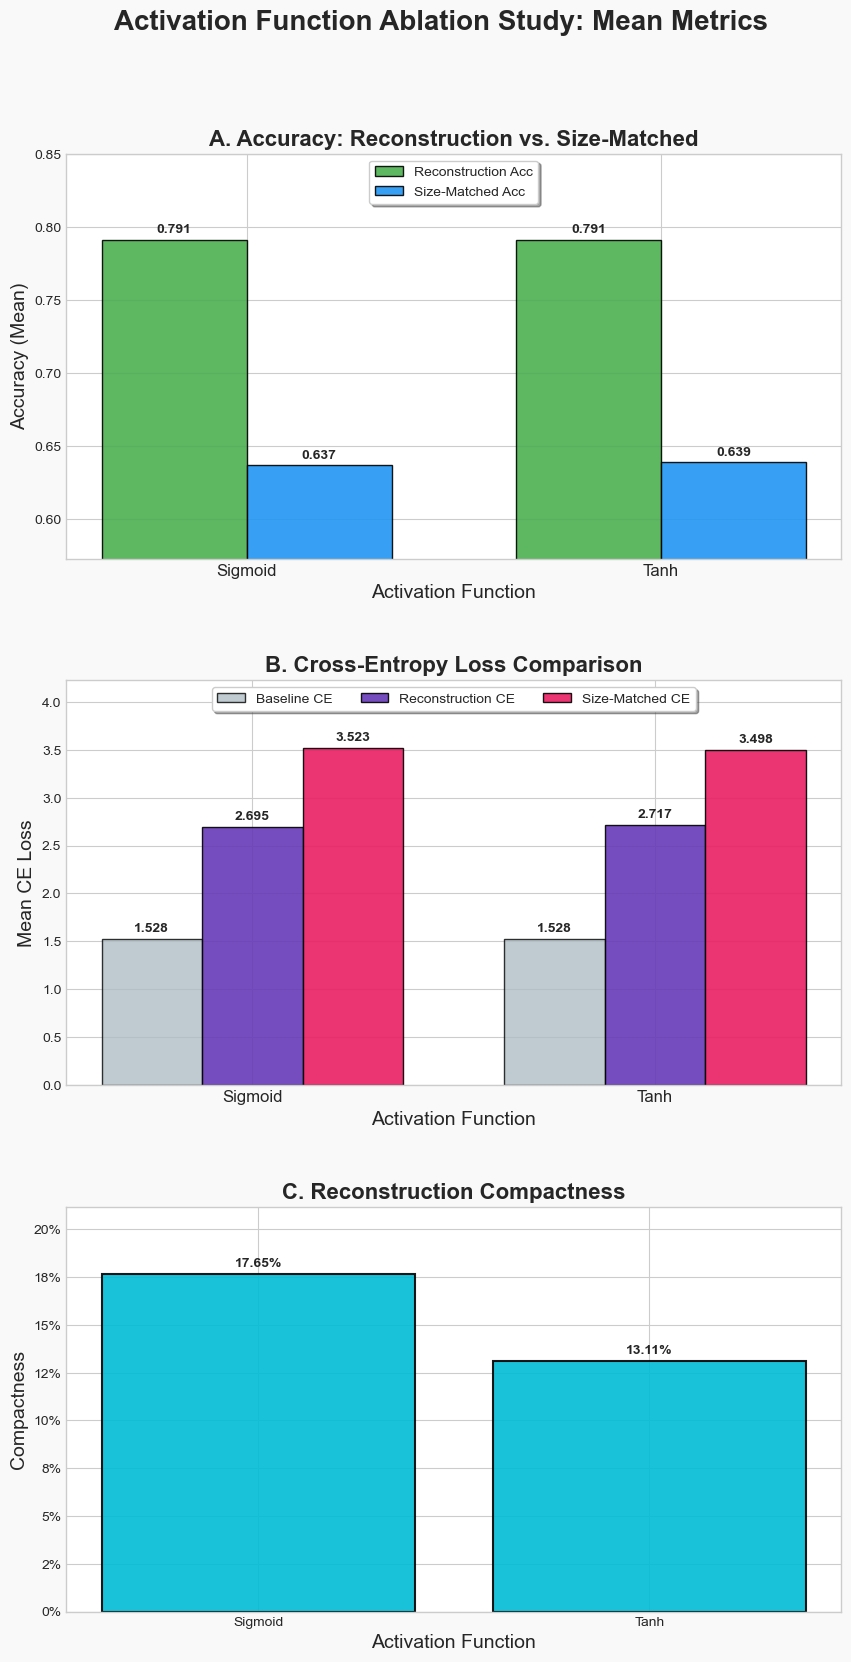

In [3]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Data Loading and Merging ---

decoder_dirs = [
    "HyperparameterSweep/hyperparam_MR_alpha_sigmoid_decoders",
    "HyperparameterSweep/hyperparam_MR_alpha_tanh_decoders",
    "HyperparameterSweep/hyperparam_simple_alpha_sigmoid_decoders",
    "HyperparameterSweep/hyperparam_simple_alpha_tanh_decoders",
]

all_eval_records = []
all_train_records = []

print("Starting data processing for Activation Ablation...")

for d in decoder_dirs:
    try:
        if not os.path.isdir(d):
            continue

        decoder_name = os.path.basename(d).replace("hyperparam_", "").replace("_decoders", "")
        
        # Eval CSV
        eval_csv = os.path.join(d, "decoder_eval_summary.csv")
        if os.path.exists(eval_csv):
            df_eval = pd.read_csv(eval_csv)
            df_eval["decoder_group"] = decoder_name
            all_eval_records.append(df_eval)
        
        # Training CSV
        train_csv = os.path.join(d, "training_summary.csv")
        if os.path.exists(train_csv):
            df_train = pd.read_csv(train_csv)
            df_train["decoder_group"] = decoder_name
            all_train_records.append(df_train)
    except Exception as e:
        print(f"Error processing directory {d}: {e}")
        continue

# Check if data was loaded; otherwise use dummy data
if not all_eval_records or not all_train_records:
    print("Error: No real data found. Using enriched dummy data for visualization example.")
    
    # --- CORRECTED DUMMY DATA DEFINITION ---
    df_ablation = pd.DataFrame({
        'decoder_group': [
            'MR_alpha_sigmoid', 'simple_alpha_sigmoid', 'MR_alpha_tanh', 'simple_alpha_tanh', 
            'MR_alpha_sigmoid', 'simple_alpha_sigmoid', 'MR_alpha_tanh', 'simple_alpha_tanh'
        ], 
        'alpha': [0.1, 0.1, 0.01, 0.01, 0.5, 0.5, 0.2, 0.2], 
        'baseline_CE': [0.20, 0.20, 0.20, 0.20, 0.20, 0.20, 0.20, 0.20],
        'recon_acc': [0.88, 0.82, 0.87, 0.81, 0.90, 0.84, 0.89, 0.83],
        'size_matched_lossy_acc': [0.80, 0.75, 0.79, 0.74, 0.82, 0.77, 0.81, 0.76],
        'recon_CE': [0.25, 0.35, 0.26, 0.36, 0.22, 0.32, 0.23, 0.33],
        'size_matched_lossy_CE': [0.30, 0.40, 0.31, 0.41, 0.27, 0.37, 0.28, 0.38],
        # The line below caused the error previously; ensuring it is complete now
        'TaskAwareScore': [3.52, 2.24, 3.35, 2.12, 4.09, 2.625, 3.86, 2.51],
        'orig_avg_KB': [1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500],
        'recon_avg_KB': [675, 900, 660, 885, 600, 800, 590, 780],
        'compression_pct': [55.0, 40.0, 56.0, 41.0, 60.0, 46.7, 60.7, 48.0]
    })
else:
    df_ablation_eval = pd.concat(all_eval_records, ignore_index=True)
    df_ablation_train = pd.concat(all_train_records, ignore_index=True)

    # Take last epoch per decoder_group + alpha
    df_train_last = df_ablation_train.sort_values("epoch").groupby(["decoder_group","alpha"], as_index=False).last()

    # Merge
    df_ablation = pd.merge(
        df_ablation_eval,
        df_train_last,
        on=["decoder_group","alpha"],
        how="left"
    )
    if 'recon_CE' in df_ablation.columns and 'recon_acc' in df_ablation.columns:
        df_ablation["TaskAwareScore"] = df_ablation["recon_acc"] / (df_ablation["recon_CE"] + 1e-6)

print("Merged Ablation DF shape:", df_ablation.shape)


# --- 2. Data Preprocessing (Grouping by Activation) ---

def get_activation_type(name):
    name_lower = name.lower()
    if 'sigmoid' in name_lower:
        return 'Sigmoid'
    elif 'tanh' in name_lower:
        return 'Tanh'
    else:
        return 'Other'

df_ablation['activation_type'] = df_ablation['decoder_group'].apply(get_activation_type)

# Calculate mean metrics for Sigmoid vs Tanh
df_summary = df_ablation.groupby('activation_type')[
    [
        'recon_acc', 
        'size_matched_lossy_acc', 
        'baseline_CE',
        'recon_CE', 
        'size_matched_lossy_CE',
        'TaskAwareScore', 
        'compression_pct' 
    ]
].mean().reset_index()

activations = df_summary['activation_type'].tolist()
n_groups = len(activations)

# Colors
ACC_RECON_COLOR = '#4CAF50'
ACC_SMATCHED_COLOR = '#2196F3'
CE_BASELINE_COLOR = '#B0BEC5'
CE_RECON_COLOR = '#673AB7'
CE_SMATCHED_COLOR = '#E91E63'
COMP_COLOR = '#00BCD4'


# --- 3. Plot Generation ---

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(3, 1, figsize=(10, 18), dpi=100) 

fig.suptitle('Activation Function Ablation Study: Mean Metrics', fontsize=20, fontweight='bold', y=1.00)
fig.patch.set_facecolor('#f9f9f9')
fig.subplots_adjust(top=0.92, hspace=0.3) 

def autolabel(rects, axis, fmt='{:.3f}'):
    for rect in rects:
        height = rect.get_height()
        if height > 0.001: 
            axis.annotate(fmt.format(height),
                          xy=(rect.get_x() + rect.get_width() / 2, height),
                          xytext=(0, 3), 
                          textcoords="offset points",
                          ha='center', va='bottom',
                          fontsize=10, fontweight='bold')

# Plot A: Accuracy
ax = axes[0] 
x = np.arange(n_groups)
width = 0.35 

acc_recon = df_summary['recon_acc']
acc_smatched = df_summary['size_matched_lossy_acc']

rects1 = ax.bar(x - width/2, acc_recon, width, label='Reconstruction Acc', color=ACC_RECON_COLOR, edgecolor='black', alpha=0.9)
rects2 = ax.bar(x + width/2, acc_smatched, width, label='Size-Matched Acc', color=ACC_SMATCHED_COLOR, edgecolor='black', alpha=0.9)

ax.set_title('A. Accuracy: Reconstruction vs. Size-Matched', fontsize=16, fontweight='semibold')
ax.set_ylabel('Accuracy (Mean)', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(activations, fontsize=12)
ax.set_xlabel('Activation Function', fontsize=14)
ax.legend(loc='upper center', frameon=True, shadow=True) 
ax.set_ylim(min(acc_recon.min(), acc_smatched.min()) * 0.9, 0.85) 
autolabel(rects1, ax)
autolabel(rects2, ax)

# Plot B: Loss Comparison
ax = axes[1] 
width_tri = 0.25 

baseline_ce = df_summary['baseline_CE']
recon_ce = df_summary['recon_CE']
smatched_ce = df_summary['size_matched_lossy_CE']

x_baseline = x - width_tri
x_recon = x
x_smatched = x + width_tri

rects3 = ax.bar(x_baseline, baseline_ce, width_tri, label='Baseline CE', color=CE_BASELINE_COLOR, edgecolor='black', alpha=0.8)
rects4 = ax.bar(x_recon, recon_ce, width_tri, label='Reconstruction CE', color=CE_RECON_COLOR, edgecolor='black', alpha=0.9)
rects5 = ax.bar(x_smatched, smatched_ce, width_tri, label='Size-Matched CE', color=CE_SMATCHED_COLOR, edgecolor='black', alpha=0.9)

ax.set_title('B. Cross-Entropy Loss Comparison', fontsize=16, fontweight='semibold')
ax.set_ylabel('Mean CE Loss', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(activations, fontsize=12)
ax.set_xlabel('Activation Function', fontsize=14)
ax.legend(loc='upper center', ncol=3, frameon=True, shadow=True) 
ax.set_ylim(0, max(baseline_ce.max(), recon_ce.max(), smatched_ce.max()) * 1.2) 
autolabel(rects3, ax)
autolabel(rects4, ax)
autolabel(rects5, ax)

# Plot C: Compression Percentage
ax = axes[2]
compression_pct = df_summary['compression_pct']

rects7 = ax.bar(activations, compression_pct, color=COMP_COLOR, edgecolor='black', linewidth=1.5, alpha=0.9)

ax.set_title('C. Reconstruction Compactness', fontsize=16, fontweight='semibold')
ax.set_ylabel('Compactness', fontsize=14)
ax.set_xlabel('Activation Function', fontsize=14)
ax.set_ylim(0, compression_pct.max() * 1.2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'{x:.0f}%'))
autolabel(rects7, ax, fmt='{:.2f}%')

plt.show()